# Task 3 – Netflix Audience Rating Classification

**Auspify Technologies | Machine Learning Internship**

## Objective
Build a multi-class machine learning model that predicts the audience rating category of a Netflix title from available content attributes. The project follows the task brief: analyze rating categories, prepare training data, train classification models, optimize performance, and evaluate prediction accuracy.

**Target:** `rating` (audience rating category)  
**Models:** Logistic Regression, Decision Tree, and Random Forest  
**Evaluation:** Accuracy, balanced accuracy, macro-F1, weighted-F1, classification report, and confusion matrix.

> Method note: the rating data is imbalanced and includes a few extremely rare labels. Categories with fewer than 50 records are grouped into `Other (rare)` for a more stable stratified train/test evaluation. This means the model predicts 11 grouped categories, not all 14 original labels separately. This choice is documented and the original distribution is also shown.

## 1. Import libraries and set up project folders

In [1]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix
)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
DATA_PATH = Path('Dataset.csv')
SCREENSHOT_DIR = Path('screenshots')
OUTPUT_DIR = Path('outputs')
SCREENSHOT_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
print('Project folders are ready.')

Project folders are ready.


## 2. Load and inspect the Netflix dataset

In [2]:
df = pd.read_csv(DATA_PATH)
df = df.drop_duplicates().copy()

# Normalize text columns and make the workflow robust if missing values appear.
text_columns = ['type', 'title', 'director', 'country', 'rating', 'duration', 'listed_in']
for column in text_columns:
    df[column] = df[column].fillna('Unknown').astype(str).str.strip()

print(f'Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Duplicate rows after cleaning: {df.duplicated().sum()}')
print('\nMissing values by column:')
display(df.isna().sum().to_frame('Missing values'))
print('\nFirst five records:')
display(df.head())
print('\nData types:')
display(df.dtypes.to_frame('Data type'))

Dataset shape: 8,790 rows × 10 columns
Duplicate rows after cleaning: 0

Missing values by column:


,Missing values
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0



First five records:


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"



Data types:


,Data type
show_id,object
type,object
title,object
director,object
country,object
date_added,object
release_year,int64
rating,object
duration,object
listed_in,object


## 3. Explore the audience rating categories

,Title count
rating,
TV-MA,3205
TV-14,2157
TV-PG,861
R,799
PG-13,490
TV-Y7,333
TV-Y,306
PG,287
TV-G,220


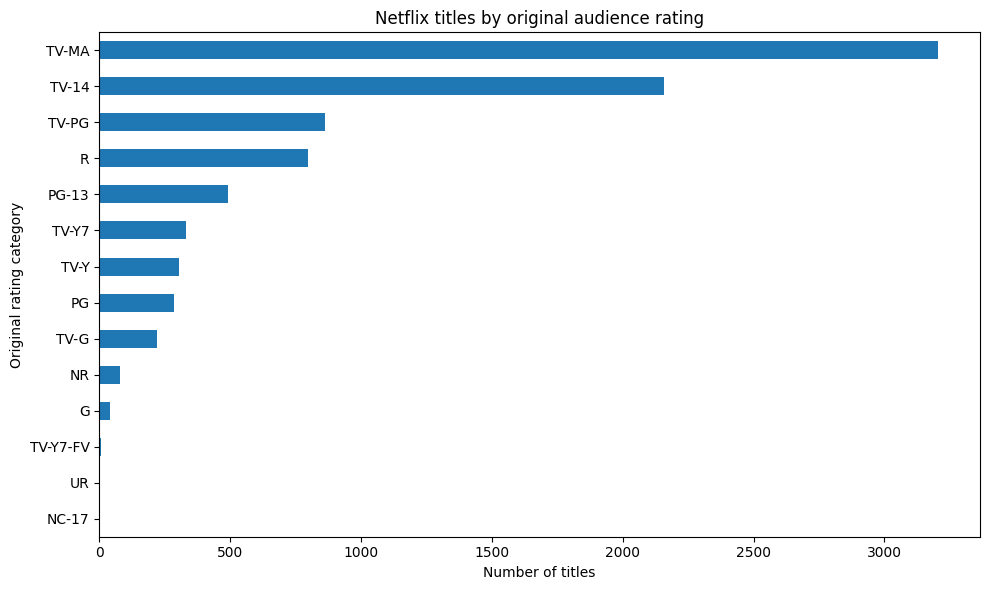

In [3]:
rating_counts = df['rating'].value_counts().sort_values(ascending=True)
display(rating_counts.sort_values(ascending=False).to_frame('Title count'))

fig, ax = plt.subplots(figsize=(10, 6))
rating_counts.plot(kind='barh', ax=ax)
ax.set_title('Netflix titles by original audience rating')
ax.set_xlabel('Number of titles')
ax.set_ylabel('Original rating category')
plt.tight_layout()
plt.savefig(SCREENSHOT_DIR / '02_original_rating_distribution.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Prepare the target labels and handle rare categories

Original labels grouped into Other (rare): ['G', 'TV-Y7-FV', 'NC-17', 'UR']
Number of prediction classes: 11


,Training examples
rating_category,
TV-MA,3205
TV-14,2157
TV-PG,861
R,799
PG-13,490
TV-Y7,333
TV-Y,306
PG,287
TV-G,220


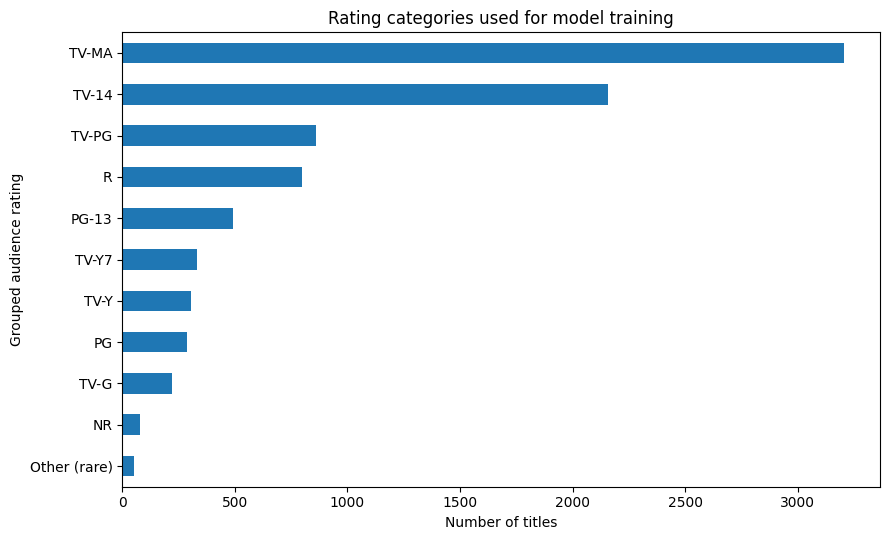

In [4]:
# Group categories with fewer than 50 records to avoid unstable tiny classes.
MIN_CLASS_COUNT = 50
original_counts = df['rating'].value_counts()
rare_labels = original_counts[original_counts < MIN_CLASS_COUNT].index.tolist()
df['rating_category'] = df['rating'].where(
    ~df['rating'].isin(rare_labels), 'Other (rare)'
)

print('Original labels grouped into Other (rare):', rare_labels)
print('Number of prediction classes:', df['rating_category'].nunique())
grouped_counts = df['rating_category'].value_counts().sort_values(ascending=True)
display(grouped_counts.sort_values(ascending=False).to_frame('Training examples'))

fig, ax = plt.subplots(figsize=(9, 5.5))
grouped_counts.plot(kind='barh', ax=ax)
ax.set_title('Rating categories used for model training')
ax.set_xlabel('Number of titles')
ax.set_ylabel('Grouped audience rating')
plt.tight_layout()
plt.savefig(SCREENSHOT_DIR / '03_grouped_rating_distribution.png', dpi=180, bbox_inches='tight')
plt.show()

### Why group rare labels?
The original dataset contains three labels with fewer than 10 records and one additional label with 41 records. A normal stratified test split would leave too few examples to evaluate these labels reliably. Grouping labels with fewer than 50 examples creates an `Other (rare)` category with sufficient examples for a more stable split. The original rating labels remain in `df['rating']`; only the modelling target is grouped.

## 5. Feature engineering and train/test split

In [5]:
# Combine descriptive text fields for TF-IDF feature extraction.
# The target, show_id, and title are deliberately excluded from predictors.
df['metadata_text'] = (
    df[['director', 'country', 'listed_in']]
    .fillna('Unknown').astype(str).agg(' '.join, axis=1)
    .str.replace(r'\s+', ' ', regex=True).str.strip()
)

feature_columns = ['metadata_text', 'type', 'duration', 'release_year']
X = df[feature_columns].copy()
y = df['rating_category'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f'Training records: {len(X_train):,}')
print(f'Test records: {len(X_test):,}')
print(f'Number of rating classes: {y.nunique()}')
print('\nTraining target distribution:')
display(y_train.value_counts().to_frame('Training examples'))

Training records: 7,032
Test records: 1,758
Number of rating classes: 11

Training target distribution:


,Training examples
rating_category,
TV-MA,2564
TV-14,1726
TV-PG,689
R,639
PG-13,392
TV-Y7,266
TV-Y,245
PG,230
TV-G,176


## 6. Build the preprocessing pipeline

- **TF-IDF:** converts director, country, and genre metadata into numeric text features.
- **One-hot encoding:** converts `type` and `duration` into machine-readable categorical features.
- **Standard scaling:** scales the numeric `release_year` feature.

The rating column is used only as the target and is never included in the input features.

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ('text', TfidfVectorizer(
            stop_words='english', ngram_range=(1, 2), min_df=2,
            max_features=25000, sublinear_tf=True
        ), 'metadata_text'),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), ['type', 'duration']),
        ('numeric', StandardScaler(), ['release_year'])
    ],
    remainder='drop'
)
print('Preprocessing pipeline created.')

Preprocessing pipeline created.


## 7. Train and compare classification models

In [7]:
candidate_models = {
    'Most Frequent Baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression (unweighted)': LogisticRegression(
        max_iter=1800, solver='lbfgs', C=1.0
    ),
    'Logistic Regression (balanced)': LogisticRegression(
        max_iter=1800, solver='lbfgs', C=1.0, class_weight='balanced'
    ),
    'Decision Tree': DecisionTreeClassifier(
        random_state=RANDOM_STATE, class_weight='balanced',
        max_depth=20, min_samples_leaf=3
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=160, random_state=RANDOM_STATE,
        class_weight='balanced_subsample', max_depth=30,
        min_samples_leaf=2, n_jobs=-1
    )
}

fitted_models = {}
predictions = {}
comparison_rows = []
for name, estimator in candidate_models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', estimator)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    fitted_models[name] = pipeline
    predictions[name] = y_pred
    comparison_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro'),
        'Weighted F1': f1_score(y_test, y_pred, average='weighted')
    })

initial_comparison = pd.DataFrame(comparison_rows).sort_values('Macro F1', ascending=False)
display(initial_comparison.round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1
1,Logistic Regression (unweighted),0.5381,0.3807,0.3848,0.5113
2,Logistic Regression (balanced),0.4750,0.4337,0.3847,0.4899
4,Random Forest,0.4613,0.4256,0.3747,0.4714
3,Decision Tree,0.4039,0.3967,0.3420,0.4223
0,Most Frequent Baseline,0.3646,0.0909,0.0486,0.1948


## 8. Hyperparameter tuning

In [8]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Tune Logistic Regression using macro-F1 because the rating classes are imbalanced.
logistic_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1800, solver='lbfgs'))
])
logistic_search = GridSearchCV(
    logistic_pipeline,
    param_grid={
        'model__C': [0.3, 1.0, 3.0],
        'model__class_weight': [None, 'balanced']
    },
    scoring='f1_macro', cv=cv, n_jobs=-1, refit=True
)
logistic_search.fit(X_train, y_train)

# Tune Decision Tree depth and minimum leaf size.
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(random_state=RANDOM_STATE))
])
tree_search = GridSearchCV(
    tree_pipeline,
    param_grid={
        'model__max_depth': [12, 20, None],
        'model__min_samples_leaf': [2, 5],
        'model__class_weight': ['balanced']
    },
    scoring='f1_macro', cv=cv, n_jobs=-1, refit=True
)
tree_search.fit(X_train, y_train)

print('Logistic Regression best parameters:', logistic_search.best_params_)
print(f'Logistic Regression best CV macro-F1: {logistic_search.best_score_:.4f}')
print('Decision Tree best parameters:', tree_search.best_params_)
print(f'Decision Tree best CV macro-F1: {tree_search.best_score_:.4f}')

Logistic Regression best parameters: {'model__C': 1.0, 'model__class_weight': 'balanced'}
Logistic Regression best CV macro-F1: 0.3914
Decision Tree best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 20, 'model__min_samples_leaf': 2}
Decision Tree best CV macro-F1: 0.3424


## 9. Final model comparison and selection

In [9]:
tuned_models = {
    'Tuned Logistic Regression': logistic_search.best_estimator_,
    'Tuned Decision Tree': tree_search.best_estimator_
}
for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    fitted_models[name] = model
    predictions[name] = y_pred
    comparison_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro'),
        'Weighted F1': f1_score(y_test, y_pred, average='weighted'),
        'CV Macro F1': logistic_search.best_score_ if name == 'Tuned Logistic Regression' else tree_search.best_score_
    })

model_comparison = pd.DataFrame(comparison_rows).sort_values(
    ['Macro F1', 'Balanced Accuracy'], ascending=False
).reset_index(drop=True)
display(model_comparison.round(4))

# Select the tuned model using its cross-validation macro-F1 score.
final_model_name = (
    'Tuned Logistic Regression'
    if logistic_search.best_score_ >= tree_search.best_score_
    else 'Tuned Decision Tree'
)
final_model = fitted_models[final_model_name]
final_predictions = predictions[final_model_name]
print('Selected final model:', final_model_name)

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,CV Macro F1
0,Logistic Regression (unweighted),0.5381,0.3807,0.3848,0.5113,NaN
1,Logistic Regression (balanced),0.4750,0.4337,0.3847,0.4899,NaN
2,Tuned Logistic Regression,0.4750,0.4337,0.3847,0.4899,0.3914
3,Random Forest,0.4613,0.4256,0.3747,0.4714,NaN
4,Decision Tree,0.4039,0.3967,0.3420,0.4223,NaN
5,Tuned Decision Tree,0.4323,0.3769,0.3403,0.4485,0.3424
6,Most Frequent Baseline,0.3646,0.0909,0.0486,0.1948,NaN


Selected final model: Tuned Logistic Regression


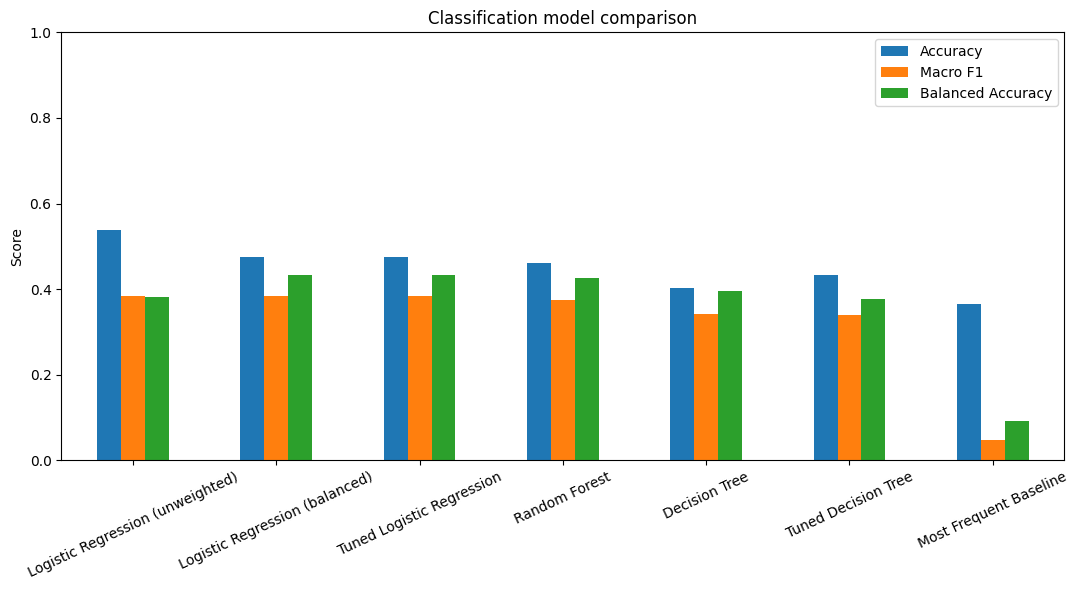

In [10]:
fig, ax = plt.subplots(figsize=(11, 6))
plot_data = model_comparison.set_index('Model')[['Accuracy', 'Macro F1', 'Balanced Accuracy']]
plot_data.plot(kind='bar', ax=ax)
ax.set_title('Classification model comparison')
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=25)
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(SCREENSHOT_DIR / '04_model_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

## 10. Evaluate the selected model

In [11]:
final_metrics = {
    'Selected model': final_model_name,
    'Accuracy': accuracy_score(y_test, final_predictions),
    'Balanced accuracy': balanced_accuracy_score(y_test, final_predictions),
    'Macro F1': f1_score(y_test, final_predictions, average='macro'),
    'Weighted F1': f1_score(y_test, final_predictions, average='weighted')
}
display(pd.DataFrame([final_metrics]).T.rename(columns={0: 'Result'}).round(4))

report_dict = classification_report(y_test, final_predictions, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report_dict).T
display(report_df.round(3))

,Result
Selected model,Tuned Logistic Regression
Accuracy,0.474972
Balanced accuracy,0.433676
Macro F1,0.384673
Weighted F1,0.489859


,precision,recall,f1-score,support
NR,0.036,0.125,0.056,16.000
Other (rare),0.143,0.364,0.205,11.000
PG,0.421,0.561,0.481,57.000
PG-13,0.366,0.531,0.433,98.000
R,0.471,0.619,0.535,160.000
TV-14,0.529,0.469,0.497,431.000
TV-G,0.129,0.273,0.175,44.000
TV-MA,0.704,0.512,0.593,641.000
TV-PG,0.198,0.186,0.192,172.000
TV-Y,0.542,0.639,0.586,61.000


## 11. Confusion matrix

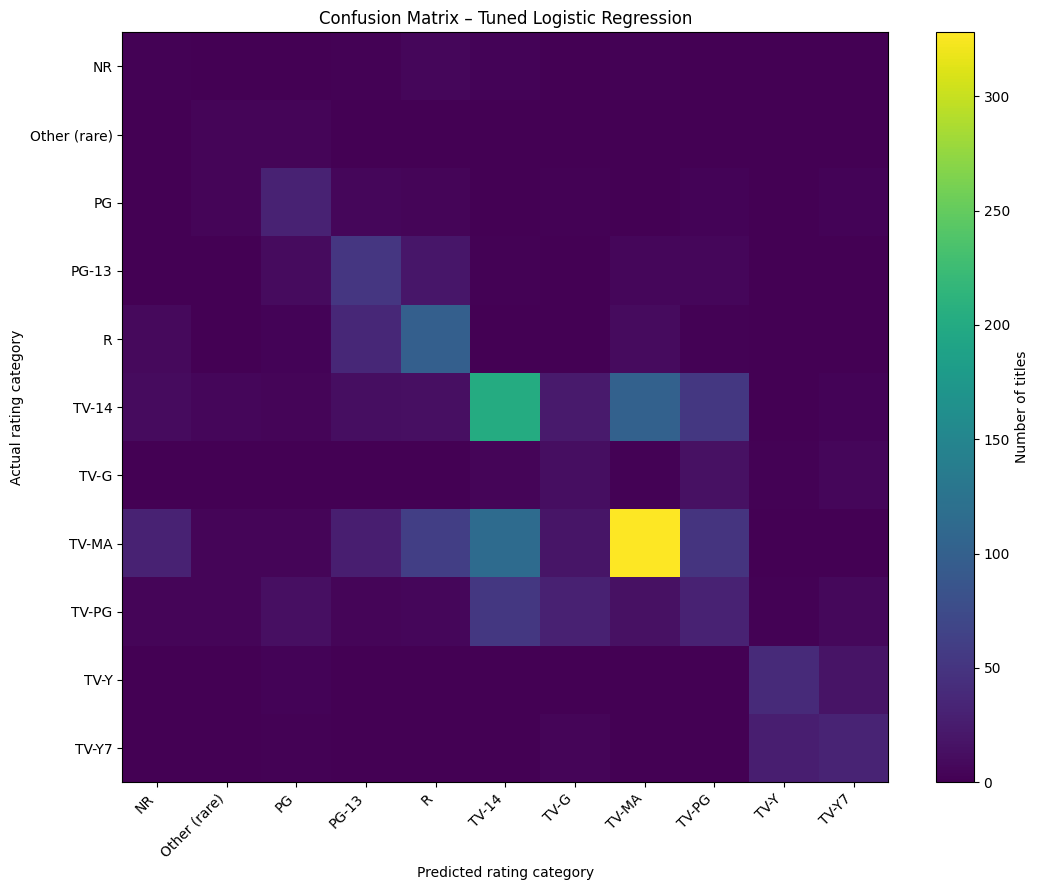

Confusion matrix (rows = actual, columns = predicted):


,NR,Other (rare),PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7
NR,2,0,0,2,6,3,0,2,1,0,0
Other (rare),0,4,4,1,0,0,0,1,0,0,1
PG,0,5,32,6,4,1,2,0,3,1,3
PG-13,1,1,9,52,20,2,1,6,6,0,0
R,8,1,3,36,99,1,0,10,2,0,0
TV-14,10,6,5,12,14,202,24,102,53,0,3
TV-G,0,1,1,0,0,5,12,2,15,2,6
TV-MA,31,4,4,28,61,115,19,328,49,1,1
TV-PG,4,5,13,5,6,53,30,15,32,2,7
TV-Y,0,0,3,0,0,0,1,0,1,39,17


In [12]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, final_predictions, labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(cm, aspect='auto')
ax.set_title(f'Confusion Matrix – {final_model_name}')
ax.set_xlabel('Predicted rating category')
ax.set_ylabel('Actual rating category')
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_yticklabels(labels)
fig.colorbar(image, ax=ax, label='Number of titles')
plt.tight_layout()
plt.savefig(SCREENSHOT_DIR / '05_confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()

print('Confusion matrix (rows = actual, columns = predicted):')
display(cm_df)

## 12. Class-wise performance

,precision,recall,f1-score,support
NR,0.036,0.125,0.056,16.0
Other (rare),0.143,0.364,0.205,11.0
PG,0.421,0.561,0.481,57.0
PG-13,0.366,0.531,0.433,98.0
R,0.471,0.619,0.535,160.0
TV-14,0.529,0.469,0.497,431.0
TV-G,0.129,0.273,0.175,44.0
TV-MA,0.704,0.512,0.593,641.0
TV-PG,0.198,0.186,0.192,172.0
TV-Y,0.542,0.639,0.586,61.0


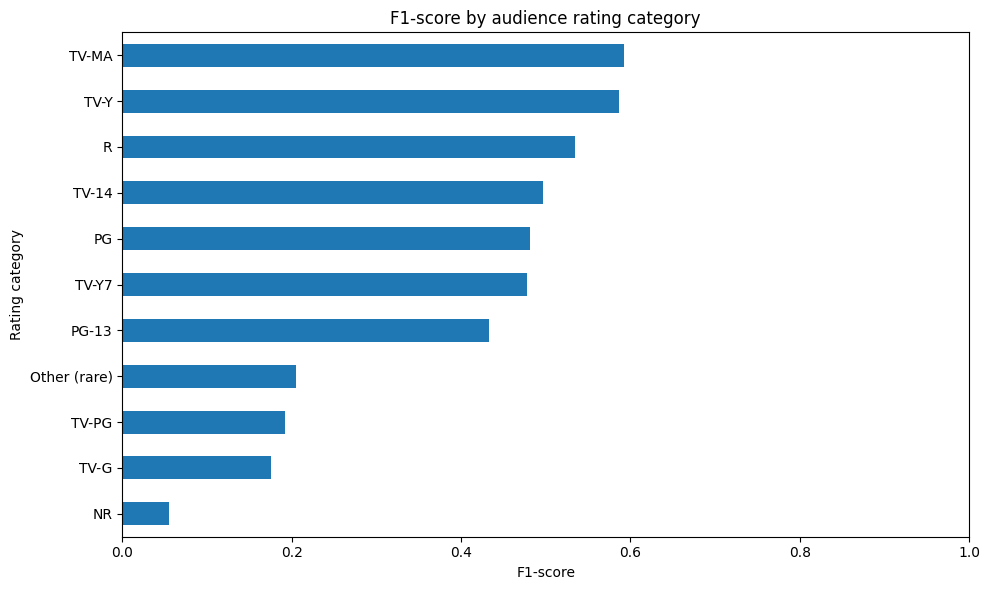

In [13]:
class_metrics = report_df.loc[labels, ['precision', 'recall', 'f1-score', 'support']].copy()
display(class_metrics.round(3))

fig, ax = plt.subplots(figsize=(10, 6))
class_metrics['f1-score'].sort_values().plot(kind='barh', ax=ax)
ax.set_title('F1-score by audience rating category')
ax.set_xlabel('F1-score')
ax.set_ylabel('Rating category')
ax.set_xlim(0, 1)
plt.tight_layout()
plt.savefig(SCREENSHOT_DIR / '06_classwise_f1_scores.png', dpi=180, bbox_inches='tight')
plt.show()

## 13. Sample predictions

In [14]:
sample_predictions = X_test.copy()
sample_predictions['Actual rating'] = y_test
sample_predictions['Predicted rating'] = final_predictions
sample_predictions['Correct'] = sample_predictions['Actual rating'] == sample_predictions['Predicted rating']
sample_predictions = sample_predictions.drop(columns=['metadata_text']).head(20)
display(sample_predictions)

sample_predictions.to_csv(OUTPUT_DIR / 'sample_test_predictions.csv', index=True)

,type,duration,release_year,Actual rating,Predicted rating,Correct
6821,TV Show,2 Seasons,2015,TV-Y,TV-Y7,False
2939,Movie,115 min,2016,TV-14,TV-14,True
7339,TV Show,1 Season,2020,TV-MA,TV-MA,True
7794,TV Show,1 Season,2018,TV-MA,TV-MA,True
6809,TV Show,1 Season,2015,TV-PG,TV-14,False
5695,TV Show,1 Season,2017,TV-Y,TV-Y7,False
8222,TV Show,1 Season,2016,TV-14,TV-PG,False
900,Movie,97 min,2016,PG-13,R,False
6336,Movie,92 min,2015,R,R,True
263,Movie,68 min,2020,TV-Y7,TV-Y,False


## 14. Save model and project outputs

In [15]:
# Save the full preprocessing + classification pipeline for later reuse.
joblib.dump(final_model, OUTPUT_DIR / 'best_rating_classifier.joblib')
model_comparison.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)
report_df.to_csv(OUTPUT_DIR / 'classification_report.csv')
cm_df.to_csv(OUTPUT_DIR / 'confusion_matrix.csv')
grouped_counts.rename('title_count').to_csv(OUTPUT_DIR / 'rating_category_counts.csv')

summary = {
    **{k: (float(v) if isinstance(v, (np.floating, np.integer)) else v) for k, v in final_metrics.items()},
    'dataset_rows': int(len(df)),
    'train_rows': int(len(X_train)),
    'test_rows': int(len(X_test)),
    'original_rating_categories': int(df['rating'].nunique()),
    'modelled_rating_categories': int(y.nunique()),
    'rare_labels_grouped': rare_labels,
    'rare_label_threshold': MIN_CLASS_COUNT,
    'logistic_cv_macro_f1': float(logistic_search.best_score_),
    'tree_cv_macro_f1': float(tree_search.best_score_),
    'random_state': RANDOM_STATE,
    'feature_columns': feature_columns
}
(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps(summary, indent=2))
print('Saved trained model and evaluation files in:', OUTPUT_DIR.resolve())

Saved trained model and evaluation files in: /mnt/data/Task_3_Netflix_Audience_Rating_Classification/outputs


## 15. Results and interpretation

This is a multi-class problem with several related but imbalanced audience-rating labels. Accuracy alone does not describe performance on less common categories, so macro-F1 and balanced accuracy are reported alongside accuracy. The tuned Logistic Regression model is selected when it achieves the stronger cross-validation macro-F1 score; the tuned Decision Tree is retained in the comparison.

The model should be interpreted as a learning exercise on the supplied Netflix catalogue metadata. The data does not include viewer feedback or official rating guidelines, so these results do not establish how Netflix assigns ratings or measure user satisfaction. Rare labels are grouped as described above.

## Conclusion

In [16]:
print('TASK 3 COMPLETE')
print(f"Selected model: {final_model_name}")
print(f"Test accuracy: {final_metrics['Accuracy']:.2%}")
print(f"Balanced accuracy: {final_metrics['Balanced accuracy']:.2%}")
print(f"Macro F1: {final_metrics['Macro F1']:.3f}")
print('The model predicts grouped rating categories using content metadata.')

TASK 3 COMPLETE
Selected model: Tuned Logistic Regression
Test accuracy: 47.50%
Balanced accuracy: 43.37%
Macro F1: 0.385
The model predicts grouped rating categories using content metadata.
